# Validação do Hodoscópio Completo — SWGO
**Múon de 5 GeV | θ = 29° | 4 ângulos azimutais | 1000 eventos cada**

Cada trajetória atravessa o cintilador no topo e o painel RPC correspondente no fundo,
validando o funcionamento conjunto do hodoscópio completo.

---

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
from scipy.optimize import curve_fit
from matplotlib.patches import Rectangle
import warnings
warnings.filterwarnings('ignore')

# Estilo acadêmico profissional
sns.set_theme(style='ticks', palette='colorblind')
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 13,
    'axes.titlesize': 15,
    'axes.labelsize': 14,
    'axes.linewidth': 0.8,
    'axes.edgecolor': 'black',
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.top': True,
    'ytick.right': True,
    'xtick.major.width': 0.8,
    'ytick.major.width': 0.8,
    'legend.framealpha': 0.9,
    'legend.edgecolor': '0.8',
    'figure.dpi': 150,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight'
})

# tab10 tem 10 cores — suficiente para os 9 ângulos
palette = sns.color_palette('tab10')

# Ângulos simulados (incluindo 20°, 23°, 25°)
ANGULOS = [0, 10, 15, 20, 23, 25, 30, 45, 60]

# Paleta de cores por ângulo (consistente em todos os plots)
CORES_ANGULO = {
    0:  palette[0],
    10: palette[1],
    15: palette[2],
    20: palette[3],
    23: palette[4],
    25: palette[5],
    30: palette[6],
    45: palette[7],
    60: palette[8],
}

print('Configurações carregadas com sucesso.')
print(f'Ângulos a analisar: {ANGULOS}')


Configurações carregadas com sucesso.
Ângulos a analisar: [0, 10, 15, 20, 23, 25, 30, 45, 60]


In [8]:
def gaussian(x, A, mu, sigma):
    return A * np.exp(-0.5 * ((x - mu) / sigma) ** 2)

def landau_approx(x, A, mu, sigma):
    """Aproximação numérica da distribuição de Landau"""
    lam = (x - mu) / sigma
    return A * np.exp(-0.5 * (lam + np.exp(-lam))) / np.sqrt(2 * np.pi)

def format_value_error(val, err):
    """Formata valor ± erro com casas decimais consistentes"""
    if err == 0 or np.isnan(err):
        return f'{val:.2f}', '—'
    mag = int(np.floor(np.log10(abs(err))))
    decimals = max(0, -mag)
    fmt = f'{{:.{decimals}f}}'
    return fmt.format(val), fmt.format(err)

def fit_and_plot(ax, data, bins, color, fit_func='gaussian', label='',
                 text_x=0.97, text_y=0.97, text_ha='right',
                 n_total=None, n_filtered=0, unit=''):
    """Plota histograma com ajuste e parâmetros na caixa de texto"""
    counts, edges = np.histogram(data, bins=bins)
    centers = (edges[:-1] + edges[1:]) / 2
    width = edges[1] - edges[0]

    ax.bar(centers, counts, width=width * 0.9, color=color, alpha=0.8,
           edgecolor='black', linewidth=0.5, label='Simulação')

    try:
        if fit_func == 'gaussian':
            p0 = [counts.max(), np.mean(data), np.std(data)]
            popt, pcov = curve_fit(gaussian, centers, counts, p0=p0, maxfev=5000)
            perr = np.sqrt(np.diag(pcov))
            x_fit = np.linspace(centers[0], centers[-1], 300)
            ax.plot(x_fit, gaussian(x_fit, *popt), color='#922B21', linewidth=1.5, label='Ajuste Gaussiano')
            mu_str, mu_err_str = format_value_error(popt[1], perr[1])
            sig_str, sig_err_str = format_value_error(abs(popt[2]), perr[2])
            n_display = n_total if n_total else len(data)
            textstr = (f'Dados do ajuste:\n'
                       f'$\\mu$ = {mu_str} ± {mu_err_str}{" " + unit if unit else ""}\n'
                       f'$\\sigma$ = {sig_str} ± {sig_err_str}\n'
                       f'N = {n_display}')
            if n_filtered > 0:
                textstr += f'\n({n_filtered} outliers removidos)'

        elif fit_func == 'landau':
            p0 = [counts.max(), np.mean(data), np.std(data)]
            popt, pcov = curve_fit(landau_approx, centers, counts, p0=p0, maxfev=5000)
            perr = np.sqrt(np.diag(pcov))
            x_fit = np.linspace(centers[0], centers[-1], 300)
            ax.plot(x_fit, landau_approx(x_fit, *popt), color='#922B21', linewidth=1.5, label='Ajuste Landau')
            mpv_str, mpv_err_str = format_value_error(popt[1], perr[1])
            sig_str, sig_err_str = format_value_error(abs(popt[2]), perr[2])
            n_display = n_total if n_total else len(data)
            textstr = (f'Dados do ajuste:\n'
                       f'MPV = {mpv_str} ± {mpv_err_str}{" " + unit if unit else ""}\n'
                       f'$\\sigma$ = {sig_str} ± {sig_err_str}\n'
                       f'N = {n_display}')
            if n_filtered > 0:
                textstr += f'\n({n_filtered} outliers removidos)'

        props = dict(boxstyle='round', facecolor='white', alpha=0.5)
        ax.text(text_x, text_y, textstr, transform=ax.transAxes, fontsize=10,
                verticalalignment='top', horizontalalignment=text_ha, bbox=props)
    except Exception as e:
        print(f'Ajuste falhou: {e}')

    return ax


def caminho_por_angulo(angulo):
    """
    Comprimento real do trajeto do múon dentro do WCD.

    Leva em conta o ponto de entrada real: o múon é lançado para passar pelo
    centro do hodoscópio (x=0, z≈97 cm), entrando na água em
    x_entry = (z_hodo - z_water_top) * tan(theta) ≈ 3.065 * tan(theta) cm.

    Para ângulos grandes, o múon sai pela parede lateral antes de atingir
    o fundo, percorrendo menos que H/cos(theta).

    Ângulo de transição (fundo → parede): ~42°
    """
    H = 187.87  # cm — altura do WCD
    R = 170.0   # cm — raio do WCD
    theta = np.radians(angulo)
    if theta == 0:
        return H

    # Ponto de entrada real na água
    # z_hodo = 97.0 cm, z_water_top = H/2 = 93.935 cm
    delta_z = 97.0 - H / 2   # ≈ 3.065 cm
    x_entry = delta_z * np.tan(theta)

    # Posição x quando o múon atingiria o fundo (z = -H/2)
    x_at_bottom = x_entry + H * np.tan(theta)

    if x_at_bottom <= R:
        # Sai pelo fundo
        return H / np.cos(theta)
    else:
        # Sai pela parede lateral (x = R)
        dx = R - x_entry
        return dx / np.sin(theta)


# Ângulo de transição fundo → parede
import math
theta_trans = math.degrees(math.atan(170.0 / (97.0 - 187.87/2 + 187.87)))
print(f'Funções auxiliares definidas.')
print(f'Ângulo de transição (fundo → parede lateral): ~{theta_trans:.1f}°')
print()
print('Comprimentos de trajeto corrigidos:')
for a in [0, 10, 15, 20, 23, 25, 30, 45, 60]:
    L = caminho_por_angulo(a)
    L_old = 187.87 / np.cos(np.radians(a)) if a < 90 else 999
    flag = '← sai pela parede' if L < L_old - 0.1 else ''
    print(f'  θ = {a:2d}°:  L = {L:.1f} cm  (H/cosθ = {L_old:.1f} cm)  {flag}')


Funções auxiliares definidas.
Ângulo de transição (fundo → parede lateral): ~41.7°

Comprimentos de trajeto corrigidos:
  θ =  0°:  L = 187.9 cm  (H/cosθ = 187.9 cm)  
  θ = 10°:  L = 190.8 cm  (H/cosθ = 190.8 cm)  
  θ = 15°:  L = 194.5 cm  (H/cosθ = 194.5 cm)  
  θ = 20°:  L = 199.9 cm  (H/cosθ = 199.9 cm)  
  θ = 23°:  L = 204.1 cm  (H/cosθ = 204.1 cm)  
  θ = 25°:  L = 207.3 cm  (H/cosθ = 207.3 cm)  
  θ = 30°:  L = 216.9 cm  (H/cosθ = 216.9 cm)  
  θ = 45°:  L = 236.1 cm  (H/cosθ = 265.7 cm)  ← sai pela parede
  θ = 60°:  L = 190.2 cm  (H/cosθ = 375.7 cm)  ← sai pela parede


In [9]:
import os
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.patches as mpatches

DATA_DIR = r'C:\Users\gizel\OneDrive\Área de Trabalho\Análises\Muon_angular_+pmt4\v09_Hodoscópio\data'
#'/home/ubuntu20/geant4-v11.1.3/v01/2026_build'

# 4 configurações de validação
CONFIGS = {
    'rpc2': {'phi': 39,  'alvo': ( 83,  66), 'label': 'RPC2 — φ=39°',  'cor': palette[0]},
    'rpc3': {'phi': 219, 'alvo': (-83, -66), 'label': 'RPC3 — φ=219°', 'cor': palette[1]},
    'rpc4': {'phi': 322, 'alvo': ( 83, -66), 'label': 'RPC4 — φ=322°', 'cor': palette[2]},
    'rpc5': {'phi': 142, 'alvo': (-83,  66), 'label': 'RPC5 — φ=142°', 'cor': palette[3]},
}

COLUNAS_DATA  = ['iEventID','EnergyDeposited_MeV','PositionX_cm','PositionY_cm',
                 'PositionZ_cm','Time_ns','EnergyElectronSec_MeV','nElectronSec',
                 'nCerenkovByMuon','nCerenkovByElectron','EdepGammas_MeV','EdepTrack_MeV']
COLUNAS_PMT   = ['iEventID','nFotonsPMT1','nFotonsPMT2','nFotonsPMT3','nFotonsPMT4']
COLUNAS_HODO  = ['iEventID','ColumnID','RowID','Edep_MeV','Time_ns']
COLUNAS_RPC   = ['iEventID','RPCID','ColumnID','RowID','Edep_MeV','Time_ns']

dados_val = {}

for key, cfg in CONFIGS.items():
    phi = cfg['phi']
    base = f'{DATA_DIR}/SWGO_muon5GeV_theta29deg_phi{phi}_1000ev'
    try:
        df      = pd.read_csv(f'{base}_nt_Data.csv',    comment='#', header=None, names=COLUNAS_DATA)
        df_pmt  = pd.read_csv(f'{base}_nt_PMTData.csv', comment='#', header=None, names=COLUNAS_PMT)
        df_hodo = pd.read_csv(f'{base}_nt_HodoData.csv',comment='#', header=None, names=COLUNAS_HODO)
        df_rpc  = pd.read_csv(f'{base}_nt_RPCData.csv', comment='#', header=None, names=COLUNAS_RPC)

        df_pmt['nFotonsTotal'] = (df_pmt['nFotonsPMT1'] + df_pmt['nFotonsPMT2'] +
                                   df_pmt['nFotonsPMT3'] + df_pmt['nFotonsPMT4'])

        dados_val[key] = {'df': df, 'df_pmt': df_pmt,
                          'df_hodo': df_hodo, 'df_rpc': df_rpc}
        print(f"  {cfg['label']:20s} → {len(df):4d} eventos | "
              f"RPC hits: {len(df_rpc)} linhas")
    except FileNotFoundError as e:
        print(f"  {key}: ARQUIVO NÃO ENCONTRADO — {e}")

print(f'\nTotal carregado: {len(dados_val)}/4 configurações')


  RPC2 — φ=39°         →  703 eventos | RPC hits: 1154 linhas
  RPC3 — φ=219°        →  705 eventos | RPC hits: 1140 linhas
  RPC4 — φ=322°        →  716 eventos | RPC hits: 1154 linhas
  RPC5 — φ=142°        →  687 eventos | RPC hits: 1131 linhas

Total carregado: 4/4 configurações


## 1. Mapas de Hits no Hodoscópio (Cintilador — Topo)

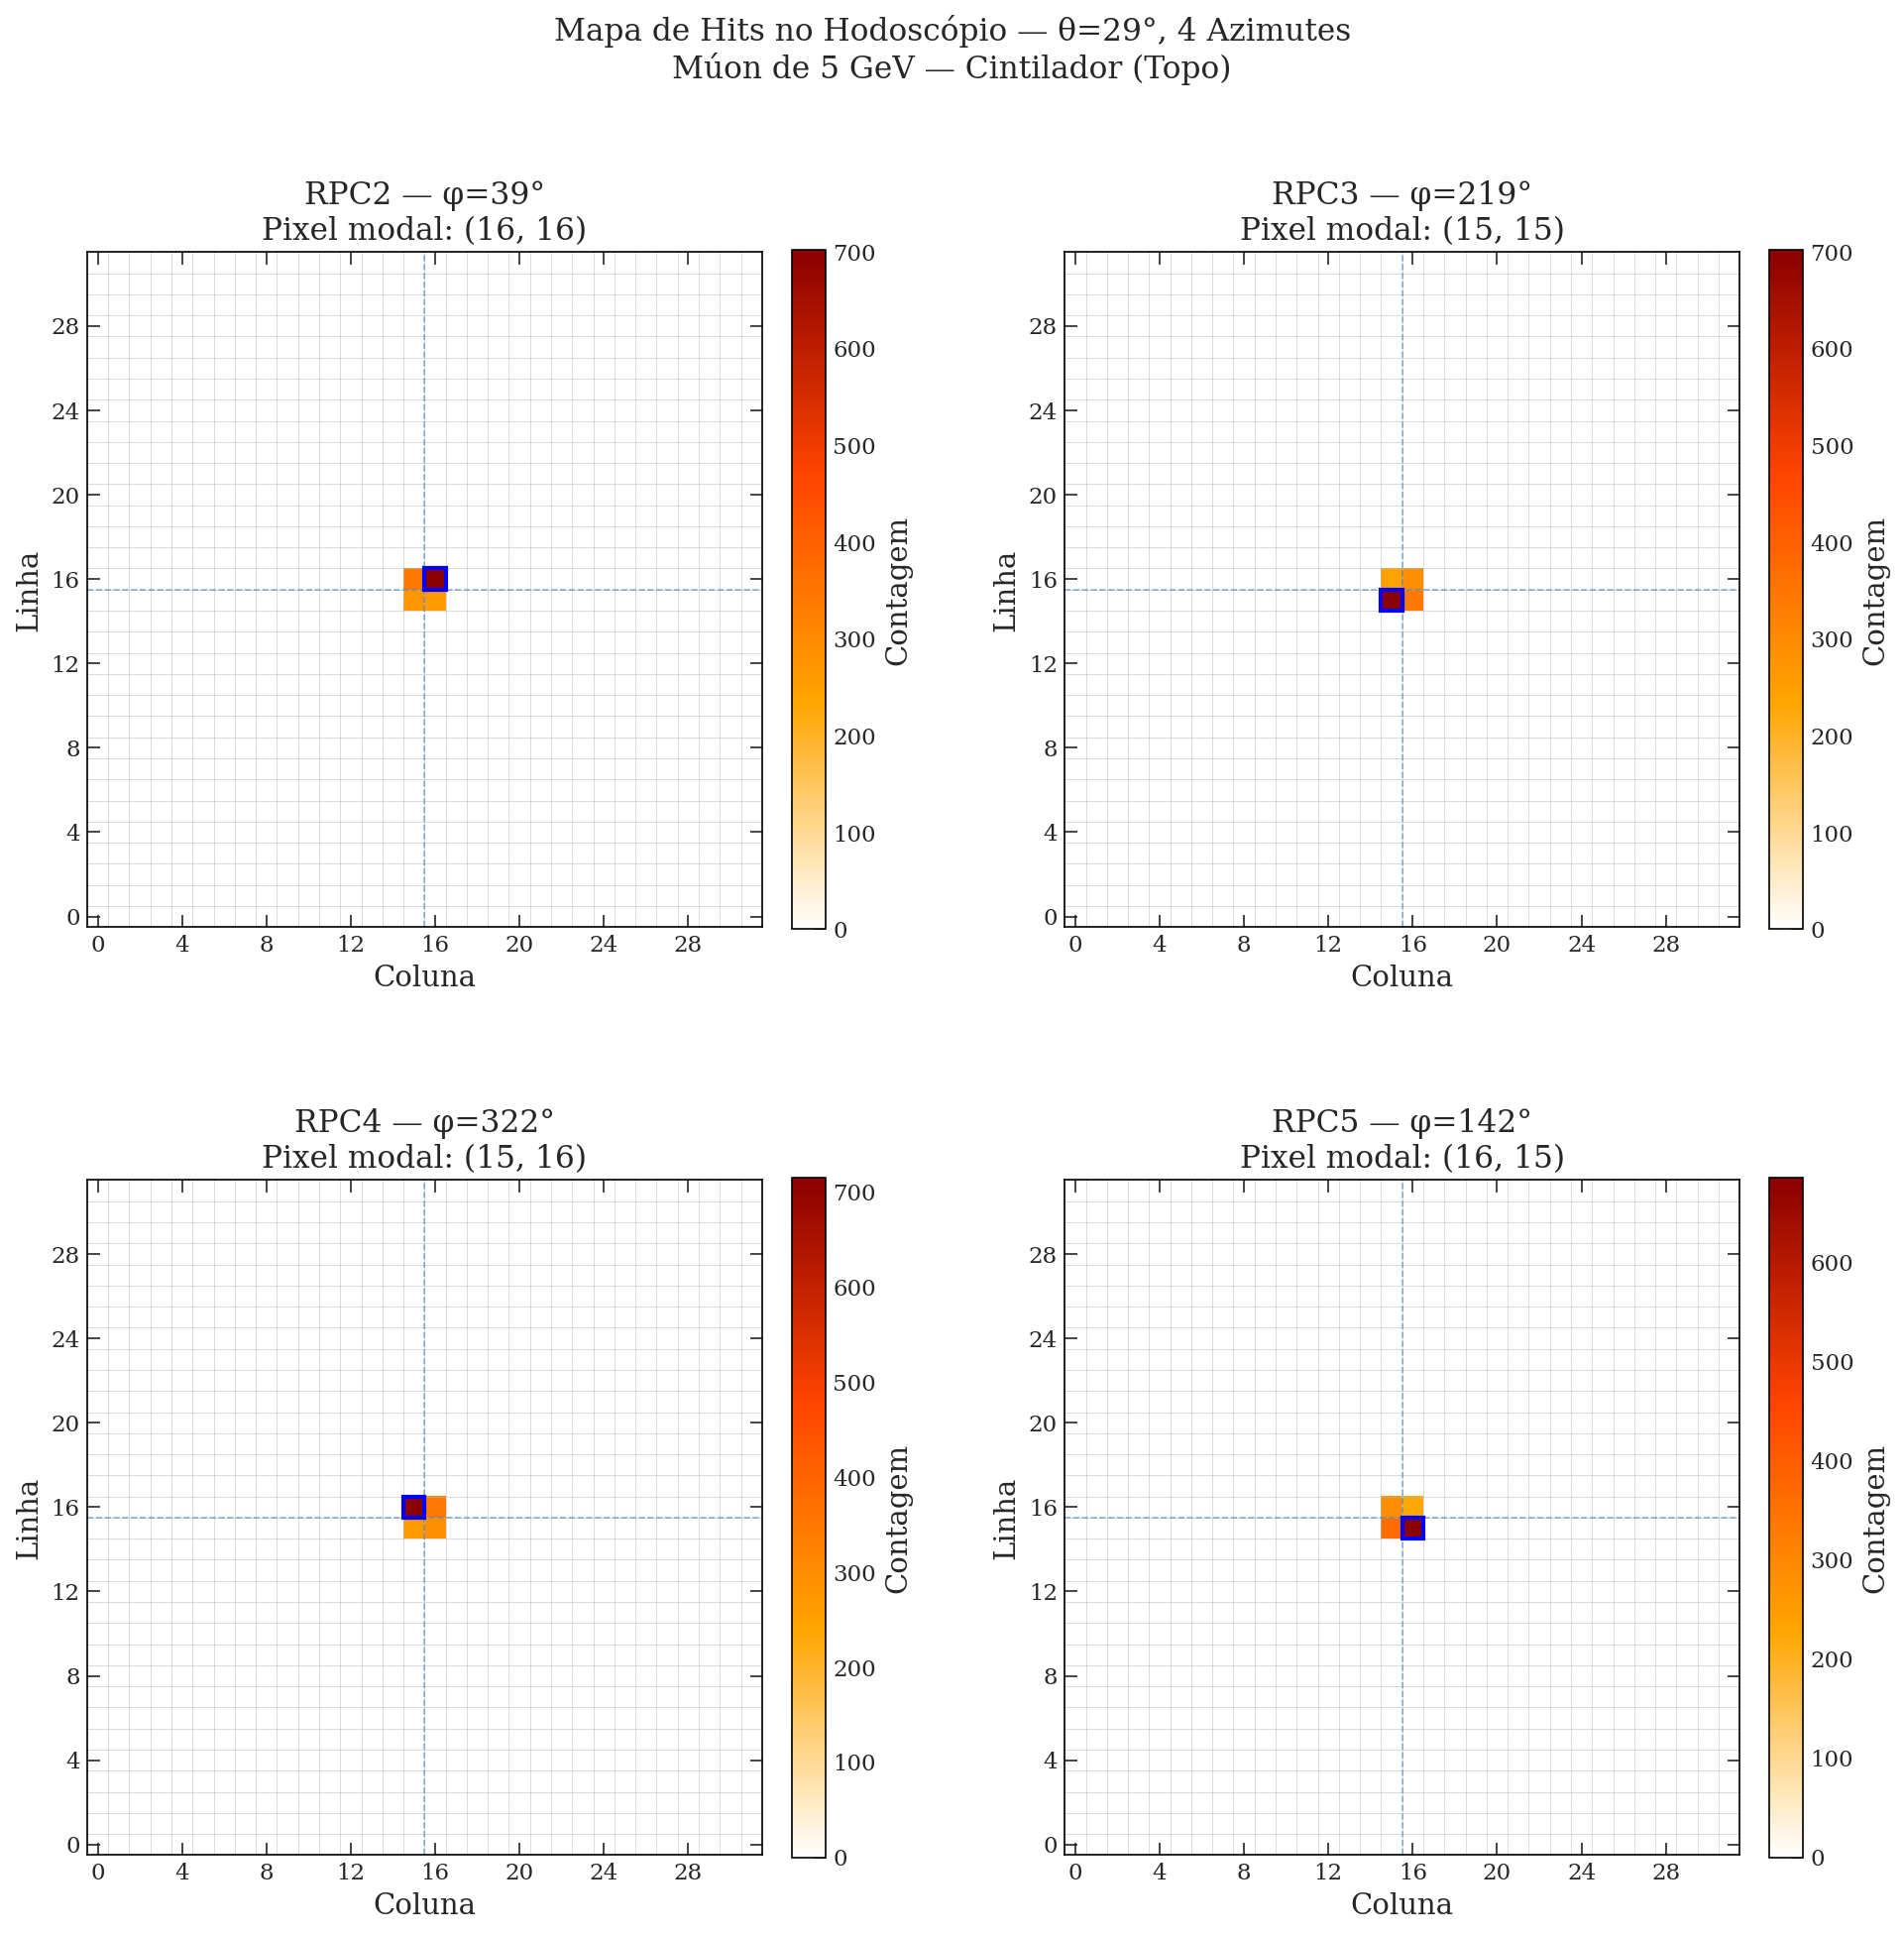

In [10]:
cmap_hodo = LinearSegmentedColormap.from_list(
    'hodo', ['white', '#FFA500', '#FF4500', '#8B0000'], N=256)

fig, axes = plt.subplots(2, 2, figsize=(13, 13))
axes = axes.flatten()

for i, (key, cfg) in enumerate(CONFIGS.items()):
    ax = axes[i]
    df_hodo = dados_val[key]['df_hodo']

    heatmap = np.zeros((32, 32))
    for _, row in df_hodo.iterrows():
        c, r = int(row['ColumnID']), int(row['RowID'])
        if 0 <= r < 32 and 0 <= c < 32:
            heatmap[r, c] += 1

    vmax = max(heatmap.max(), 1)
    im = ax.imshow(heatmap, cmap=cmap_hodo, origin='lower',
                   interpolation='nearest', aspect='equal',
                   vmin=0, vmax=vmax)

    # Grade dos pixels
    ax.set_xticks(np.arange(-0.5, 32, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, 32, 1), minor=True)
    ax.grid(which='minor', color='#bbbbbb', linewidth=0.25)
    ax.tick_params(which='minor', size=0)
    ax.set_xticks(np.arange(0, 32, 4))
    ax.set_yticks(np.arange(0, 32, 4))

    # Pixel modal
    col_mode = df_hodo['ColumnID'].mode()[0]
    row_mode = df_hodo['RowID'].mode()[0]
    rect = mpatches.Rectangle((col_mode - 0.5, row_mode - 0.5), 1, 1,
                               fill=False, edgecolor='blue', linewidth=2, zorder=5)
    ax.add_patch(rect)

    # Centro geométrico
    ax.axvline(x=15.5, color='steelblue', linewidth=0.8, linestyle='--', alpha=0.6)
    ax.axhline(y=15.5, color='steelblue', linewidth=0.8, linestyle='--', alpha=0.6)

    plt.colorbar(im, ax=ax, label='Contagem', fraction=0.046, pad=0.04)
    ax.set_xlabel('Coluna')
    ax.set_ylabel('Linha')
    ax.set_title(f'{cfg["label"]}\nPixel modal: ({col_mode}, {row_mode})')

plt.suptitle('Mapa de Hits no Hodoscópio — θ=29°, 4 Azimutes\n'
             'Múon de 5 GeV — Cintilador (Topo)', fontsize=15, y=1.01)
plt.tight_layout(h_pad=3, w_pad=3)
plt.savefig('validacao_hodoscopio.png', dpi=300, bbox_inches='tight')
plt.show()


## 2. Mapas de Hits nas RPCs (Fundo)

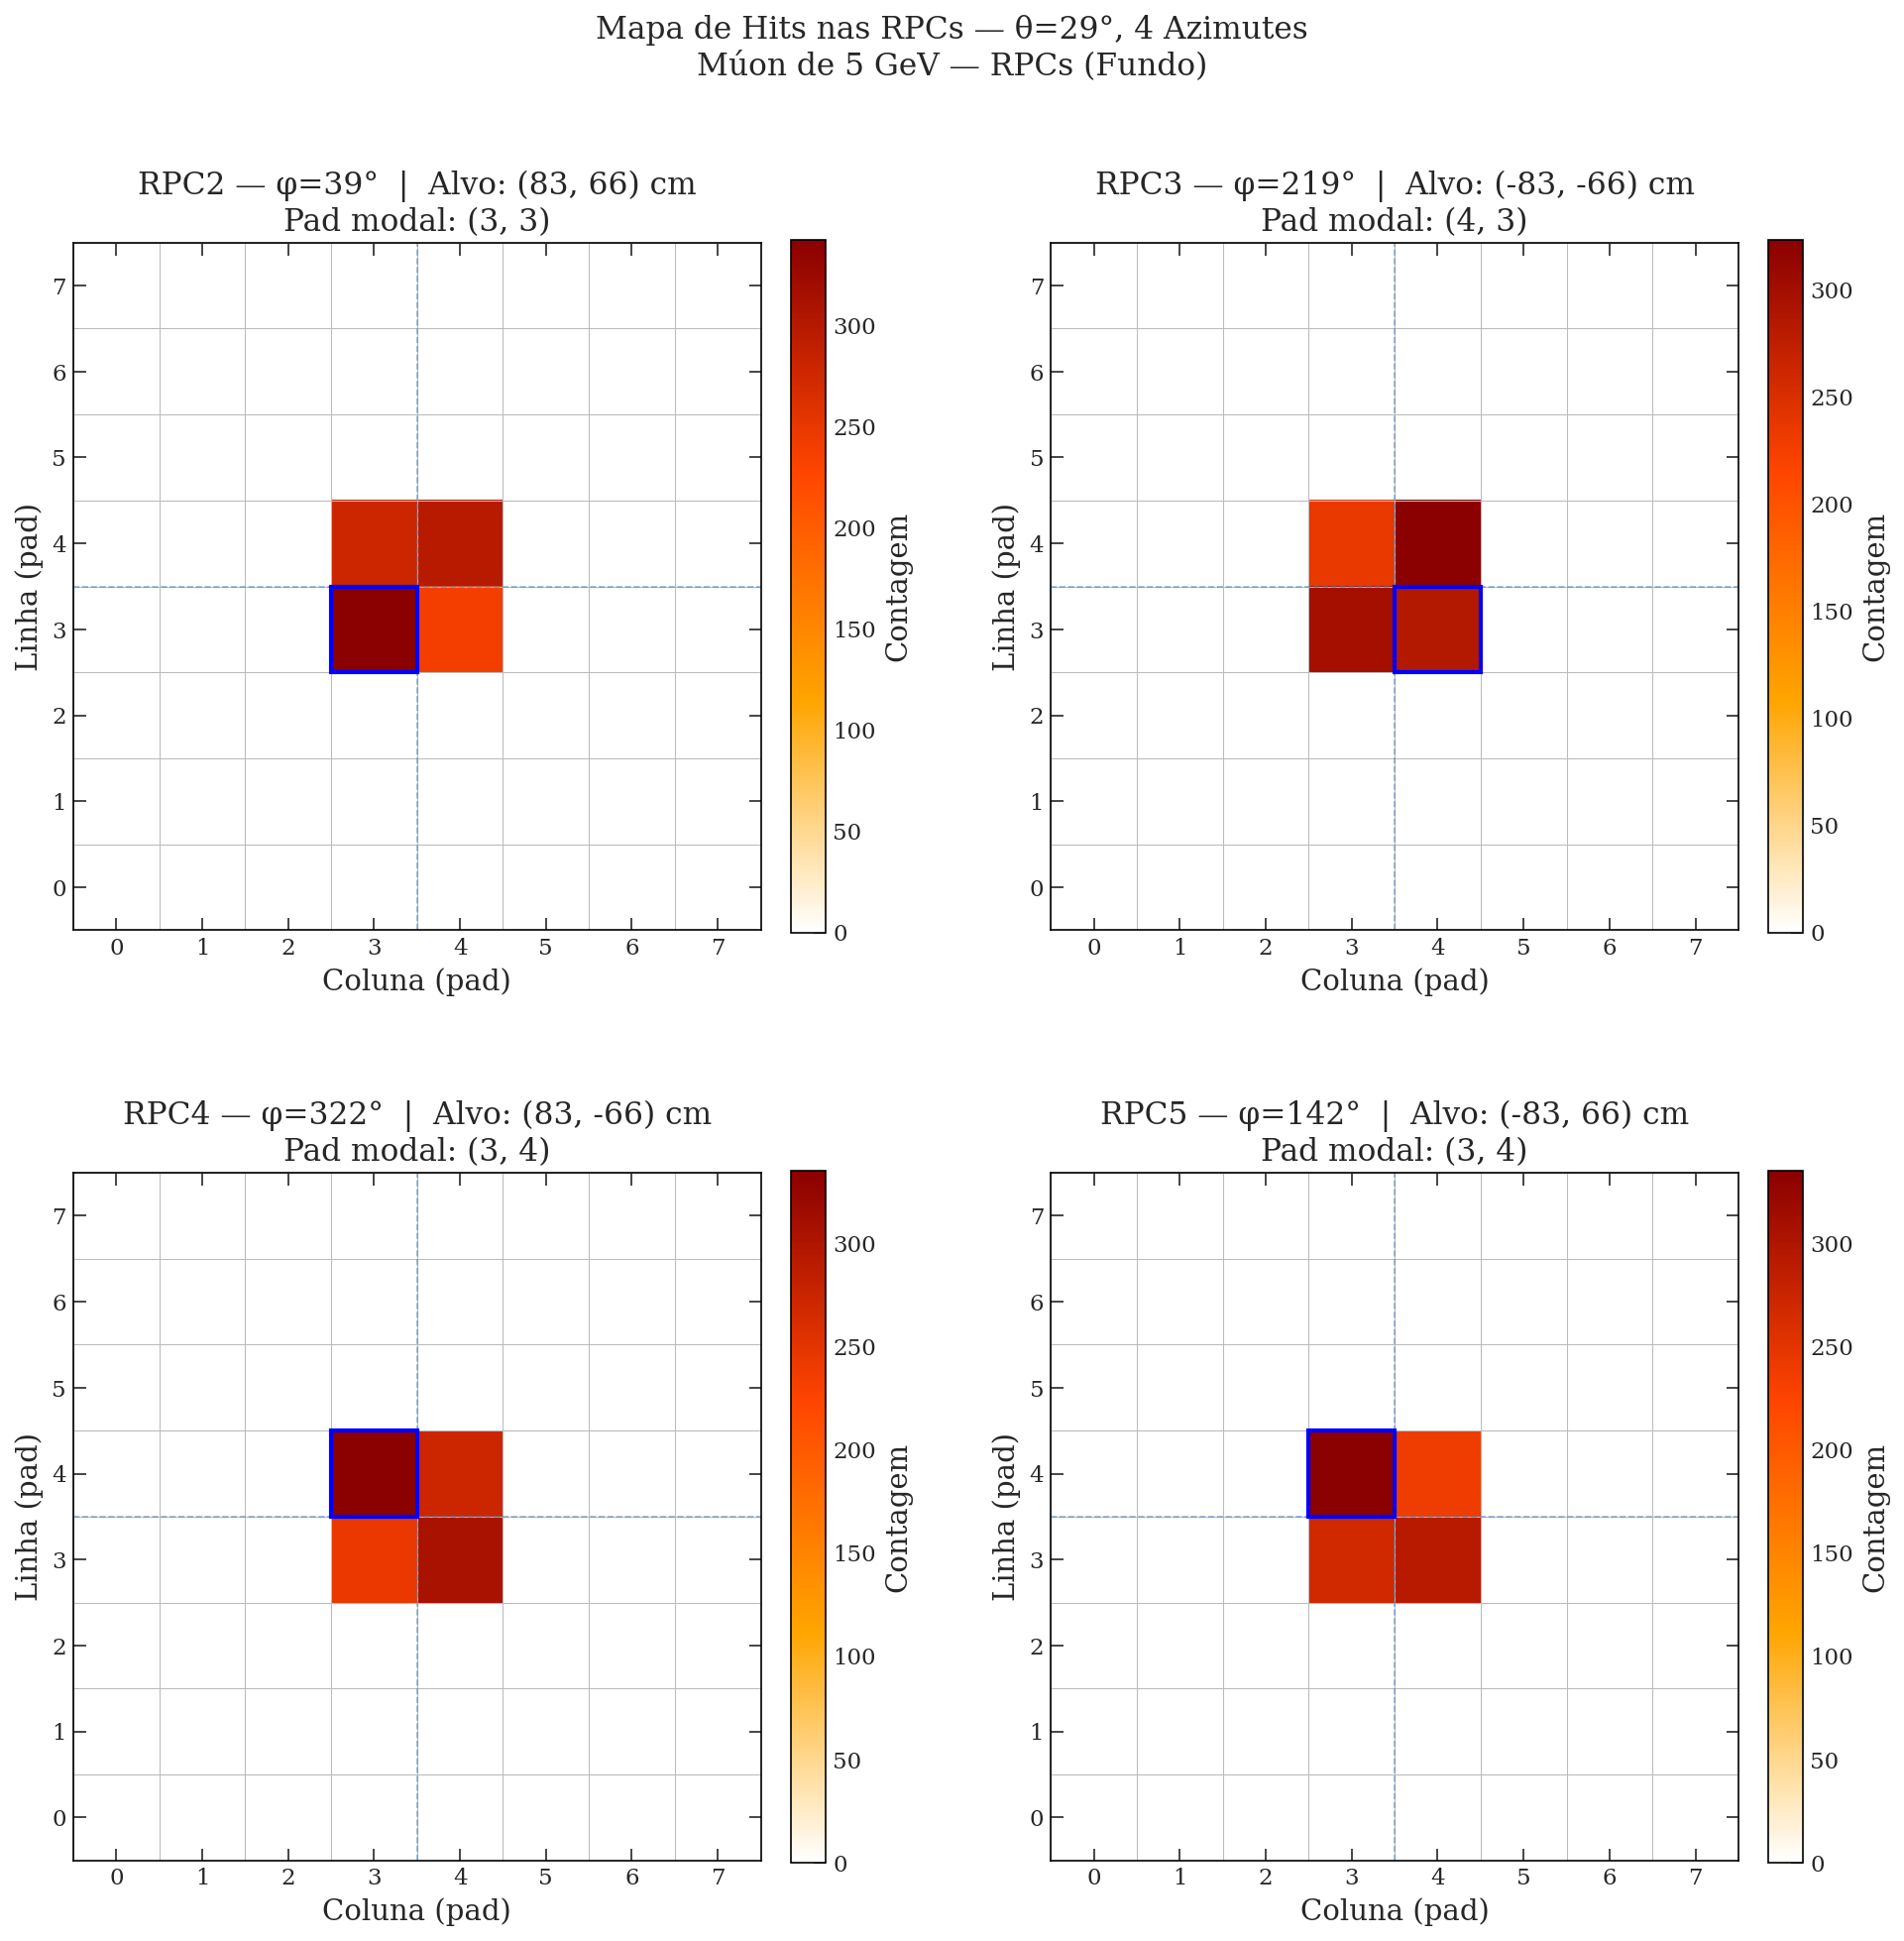

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(13, 13))
axes = axes.flatten()

# Tamanho da grade RPC: 8x8 pads por painel
for i, (key, cfg) in enumerate(CONFIGS.items()):
    ax = axes[i]
    df_rpc  = dados_val[key]['df_rpc']
    alvo    = cfg['alvo']

    heatmap_rpc = np.zeros((8, 8))
    for _, row in df_rpc.iterrows():
        c, r = int(row['ColumnID']), int(row['RowID'])
        if 0 <= r < 8 and 0 <= c < 8:
            heatmap_rpc[r, c] += 1

    vmax = max(heatmap_rpc.max(), 1)
    im = ax.imshow(heatmap_rpc, cmap=cmap_hodo, origin='lower',
                   interpolation='nearest', aspect='equal',
                   vmin=0, vmax=vmax)

    # Grade dos pads
    ax.set_xticks(np.arange(-0.5, 8, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, 8, 1), minor=True)
    ax.grid(which='minor', color='#bbbbbb', linewidth=0.5)
    ax.tick_params(which='minor', size=0)
    ax.set_xticks(np.arange(0, 8, 1))
    ax.set_yticks(np.arange(0, 8, 1))

    # Pad modal
    if len(df_rpc) > 0:
        col_mode = df_rpc['ColumnID'].mode()[0]
        row_mode = df_rpc['RowID'].mode()[0]
        rect = mpatches.Rectangle((col_mode - 0.5, row_mode - 0.5), 1, 1,
                                   fill=False, edgecolor='blue', linewidth=2, zorder=5)
        ax.add_patch(rect)
        title_extra = f'Pad modal: ({col_mode}, {row_mode})'
    else:
        title_extra = 'Sem hits'

    # Centro geométrico
    ax.axvline(x=3.5, color='steelblue', linewidth=0.8, linestyle='--', alpha=0.6)
    ax.axhline(y=3.5, color='steelblue', linewidth=0.8, linestyle='--', alpha=0.6)

    plt.colorbar(im, ax=ax, label='Contagem', fraction=0.046, pad=0.04)
    ax.set_xlabel('Coluna (pad)')
    ax.set_ylabel('Linha (pad)')
    ax.set_title(f'{cfg["label"]}  |  Alvo: {alvo} cm\n{title_extra}')

plt.suptitle('Mapa de Hits nas RPCs — θ=29°, 4 Azimutes\n'
             'Múon de 5 GeV — RPCs (Fundo)', fontsize=15, y=1.01)
plt.tight_layout(h_pad=3, w_pad=3)
plt.savefig('validacao_rpc.png', dpi=300, bbox_inches='tight')
plt.show()


## 3. Energia Depositada no WCD — θ=29°

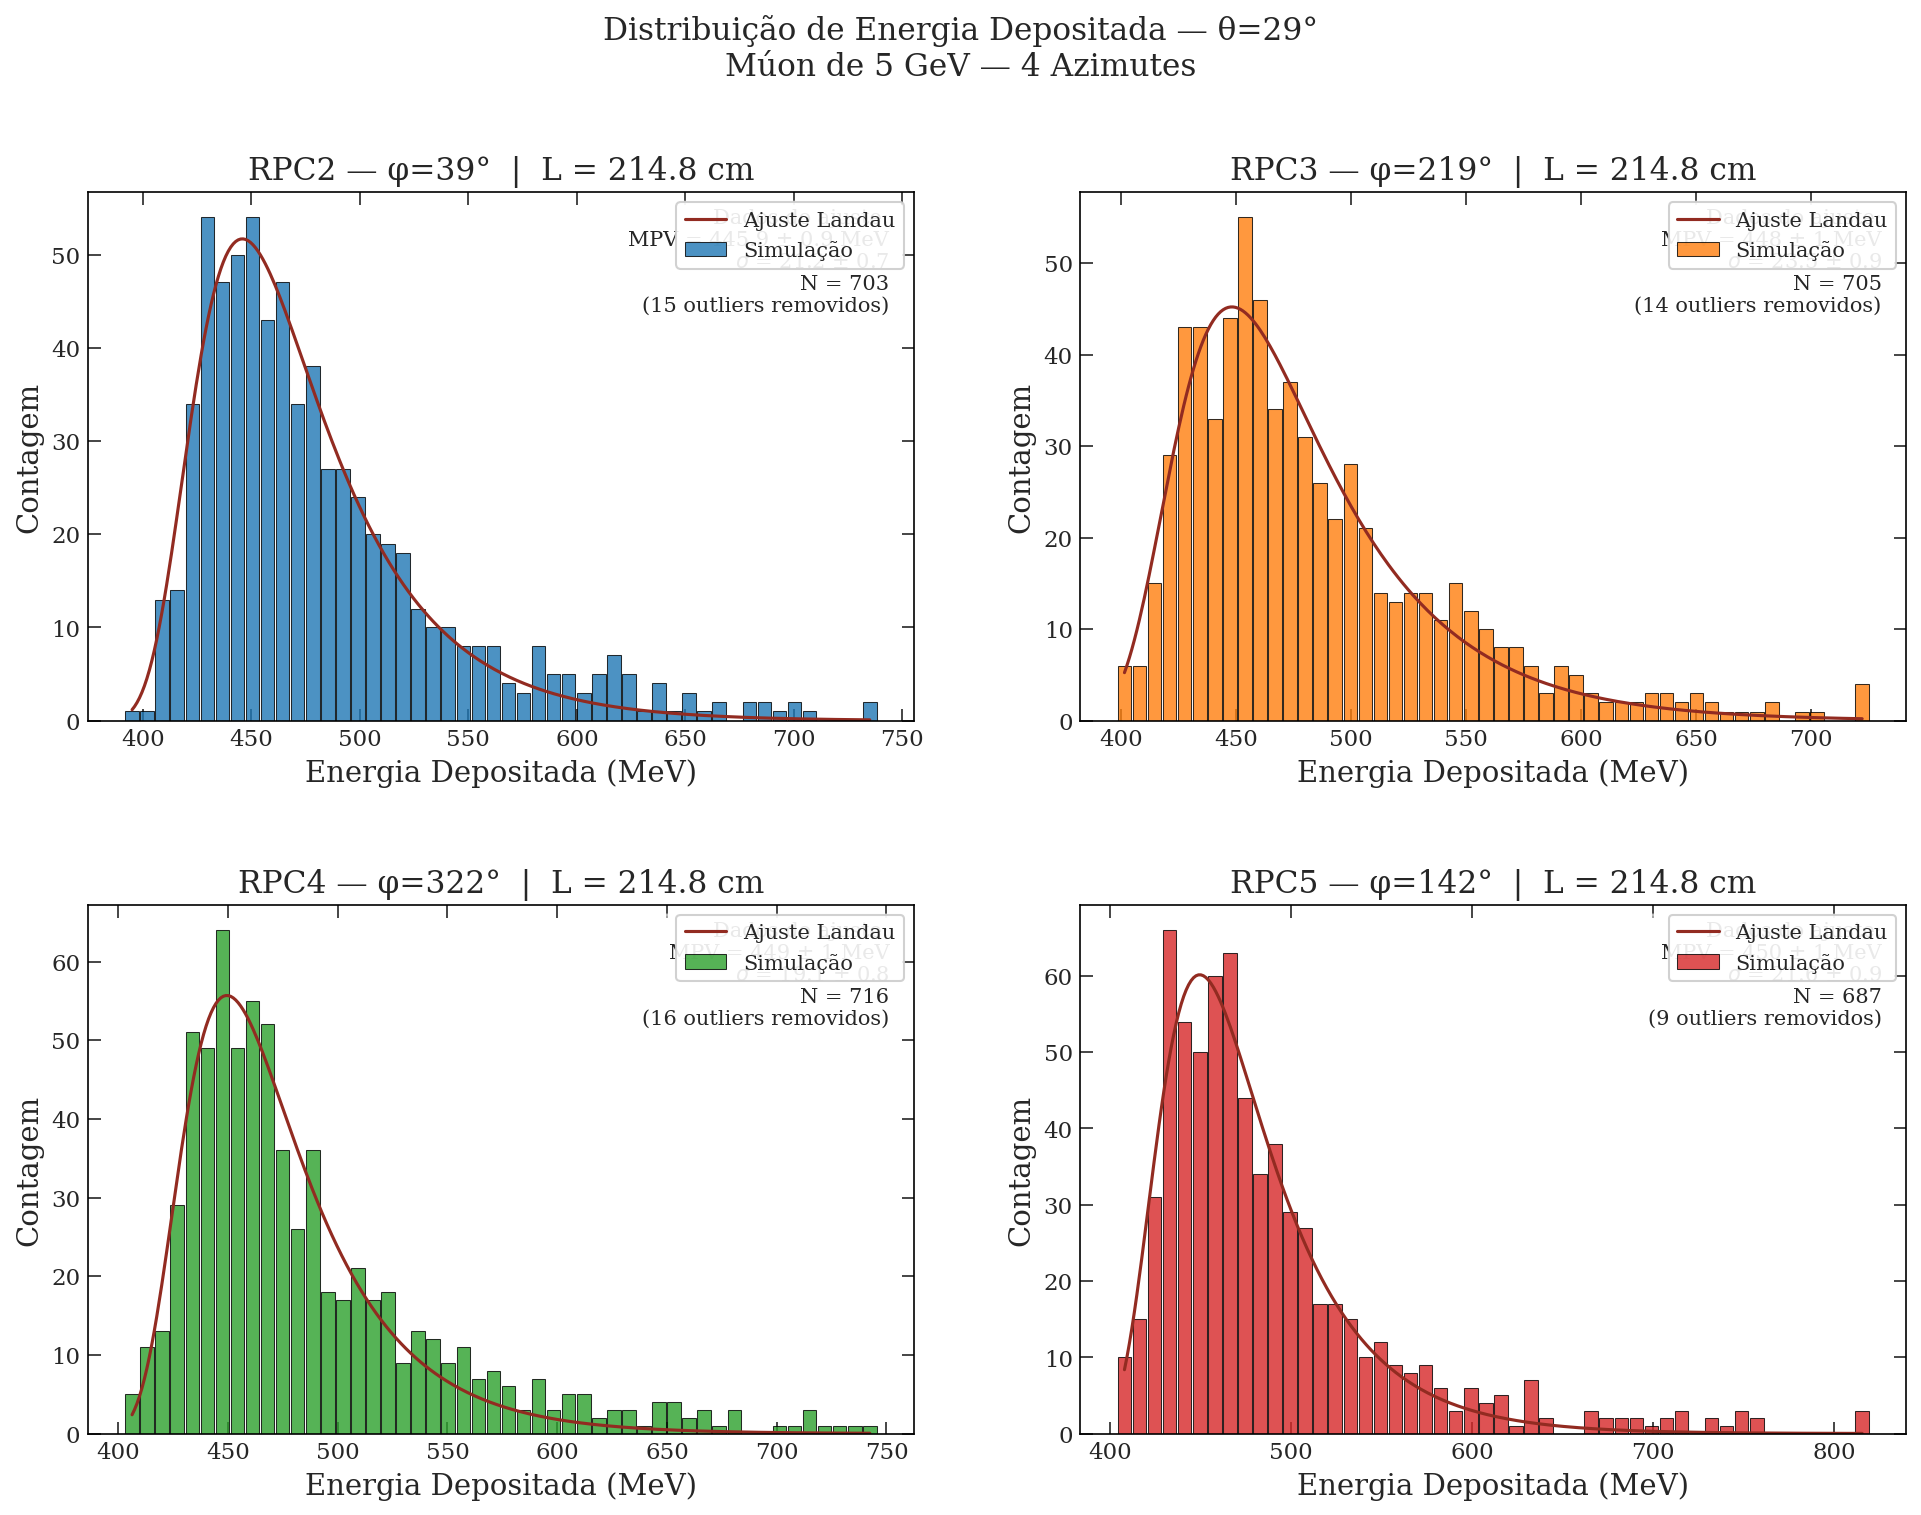

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
axes = axes.flatten()

L_29 = caminho_por_angulo(29)

for i, (key, cfg) in enumerate(CONFIGS.items()):
    ax = axes[i]
    edep = dados_val[key]['df']['EnergyDeposited_MeV']
    edep_filt = edep[edep < edep.mean() + 3*edep.std()]
    fit_and_plot(ax, edep_filt, bins=50, color=cfg['cor'],
                 fit_func='landau', text_x=0.97, text_y=0.97, text_ha='right',
                 n_total=len(edep), n_filtered=len(edep)-len(edep_filt), unit='MeV')
    ax.set_xlabel('Energia Depositada (MeV)')
    ax.set_ylabel('Contagem')
    ax.set_title(f'{cfg["label"]}  |  L = {L_29:.1f} cm')
    ax.legend(fontsize=10)

plt.suptitle('Distribuição de Energia Depositada — θ=29°\n'
             'Múon de 5 GeV — 4 Azimutes', fontsize=15, y=1.01)
plt.tight_layout(h_pad=3, w_pad=3)
plt.savefig('validacao_energia.png', dpi=300, bbox_inches='tight')
plt.show()


## 4. Resposta das PMTs — θ=29°

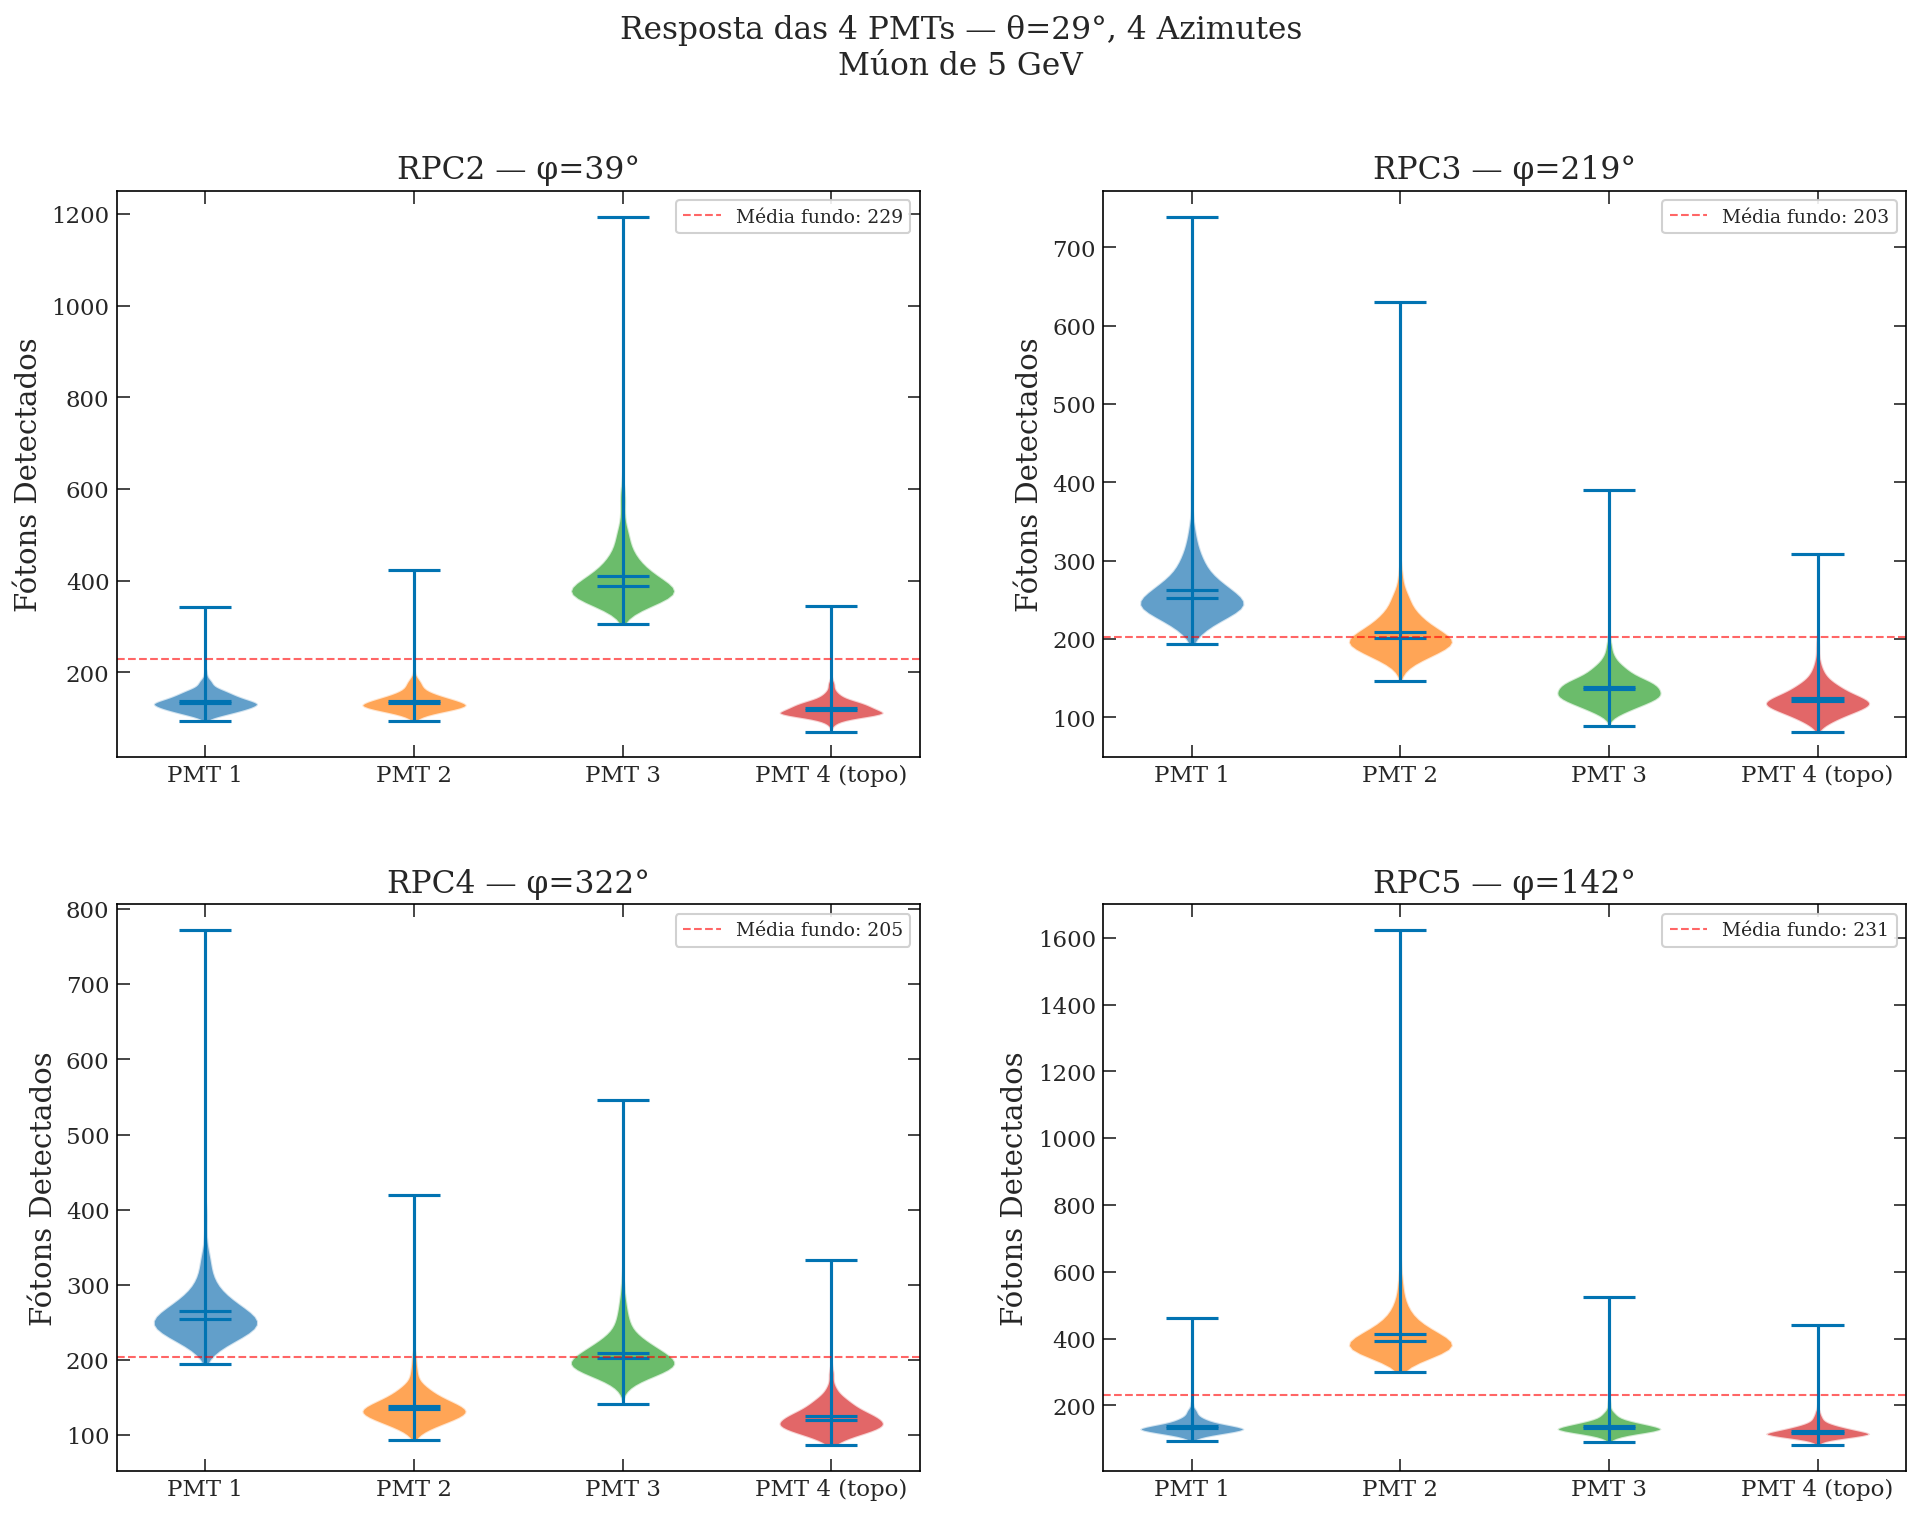

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
axes = axes.flatten()

for i, (key, cfg) in enumerate(CONFIGS.items()):
    ax = axes[i]
    df_pmt = dados_val[key]['df_pmt']
    data_v = [df_pmt['nFotonsPMT1'], df_pmt['nFotonsPMT2'],
              df_pmt['nFotonsPMT3'], df_pmt['nFotonsPMT4']]
    vp = ax.violinplot(data_v, positions=[1,2,3,4], showmeans=True, showmedians=True)
    for j, pc in enumerate(vp['bodies']):
        pc.set_facecolor([palette[0],palette[1],palette[2],palette[3]][j])
        pc.set_alpha(0.7)
    media_fundo = df_pmt[['nFotonsPMT1','nFotonsPMT2','nFotonsPMT3']].values.mean()
    ax.axhline(media_fundo, color='red', linestyle='--', linewidth=1,
               alpha=0.6, label=f'Média fundo: {media_fundo:.0f}')
    ax.set_xticks([1,2,3,4])
    ax.set_xticklabels(['PMT 1','PMT 2','PMT 3','PMT 4 (topo)'])
    ax.set_ylabel('Fótons Detectados')
    ax.set_title(cfg['label'])
    ax.legend(fontsize=9)

plt.suptitle('Resposta das 4 PMTs — θ=29°, 4 Azimutes\n'
             'Múon de 5 GeV', fontsize=15, y=1.01)
plt.tight_layout(h_pad=3, w_pad=3)
plt.savefig('validacao_pmts.png', dpi=300, bbox_inches='tight')
plt.show()


## 5. Resumo da Validação

In [14]:
print('=' * 80)
print('RESUMO — VALIDAÇÃO DO HODOSCÓPIO COMPLETO')
print(f'θ = 29°  |  Múon de 5 GeV  |  L = {caminho_por_angulo(29):.1f} cm  |  1000 eventos')
print('=' * 80)
print(f'{"Config":>12} | {"Hodo modal":>12} | {"RPC modal":>10} | '
      f'{"Edep (MeV)":>12} | {"PMTs total":>11} | {"RPC hits":>9}')
print('-' * 80)

for key, cfg in CONFIGS.items():
    d = dados_val[key]
    # Hodoscope modal pixel
    col_h = d['df_hodo']['ColumnID'].mode()[0]
    row_h = d['df_hodo']['RowID'].mode()[0]
    # RPC modal pad
    if len(d['df_rpc']) > 0:
        col_r = d['df_rpc']['ColumnID'].mode()[0]
        row_r = d['df_rpc']['RowID'].mode()[0]
        rpc_modal = f'({col_r},{row_r})'
        rpc_hits  = len(d['df_rpc'])
    else:
        rpc_modal = '—'
        rpc_hits  = 0
    edep_mean = d['df']['EnergyDeposited_MeV'].mean()
    edep_std  = d['df']['EnergyDeposited_MeV'].std()
    pmt_total = d['df_pmt']['nFotonsTotal'].mean()

    v_e, e_e = format_value_error(edep_mean, edep_std)
    print(f'{cfg["label"]:>12} | ({col_h:2d},{row_h:2d})      | '
          f'{rpc_modal:>10} | {v_e:>6} ± {e_e:<5} | '
          f'{pmt_total:>10.1f} | {rpc_hits:>9}')

print('=' * 80)
print()
print('Verificação geométrica:')
print('  Hodoscópio: pixel modal deve ser próximo ao centro (15,15)')
print('  RPC: pad modal deve ser próximo ao centro (3,3) ou (4,4)')
print('  Energia depositada: ~500 MeV esperado para θ=29°')


RESUMO — VALIDAÇÃO DO HODOSCÓPIO COMPLETO
θ = 29°  |  Múon de 5 GeV  |  L = 214.8 cm  |  1000 eventos
      Config |   Hodo modal |  RPC modal |   Edep (MeV) |  PMTs total |  RPC hits
--------------------------------------------------------------------------------
RPC2 — φ=39° | (16,16)      |      (3,3) |    491 ± 85    |      809.0 |      1154
RPC3 — φ=219° | (15,15)      |      (4,3) |    491 ± 79    |      734.3 |      1140
RPC4 — φ=322° | (15,16)      |      (3,4) |    496 ± 87    |      738.7 |      1154
RPC5 — φ=142° | (16,15)      |      (3,4) |    498 ± 108   |      817.8 |      1131

Verificação geométrica:
  Hodoscópio: pixel modal deve ser próximo ao centro (15,15)
  RPC: pad modal deve ser próximo ao centro (3,3) ou (4,4)
  Energia depositada: ~500 MeV esperado para θ=29°
